## TomekLinks for removing overlapping in data

TomekLinks is more or less automatic tool, no parameters to adjust.

In [1]:
import pandas as pd

df = pd.read_csv("../winequality-red.csv")
df

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,7.4,0.700,0.00,1.9,0.076,11.0,34.0,0.99780,3.51,0.56,9.4,5
1,7.8,0.880,0.00,2.6,0.098,25.0,67.0,0.99680,3.20,0.68,9.8,5
2,7.8,0.760,0.04,2.3,0.092,15.0,54.0,0.99700,3.26,0.65,9.8,5
3,11.2,0.280,0.56,1.9,0.075,17.0,60.0,0.99800,3.16,0.58,9.8,6
4,7.4,0.700,0.00,1.9,0.076,11.0,34.0,0.99780,3.51,0.56,9.4,5
...,...,...,...,...,...,...,...,...,...,...,...,...
1594,6.2,0.600,0.08,2.0,0.090,32.0,44.0,0.99490,3.45,0.58,10.5,5
1595,5.9,0.550,0.10,2.2,0.062,39.0,51.0,0.99512,3.52,0.76,11.2,6
1596,6.3,0.510,0.13,2.3,0.076,29.0,40.0,0.99574,3.42,0.75,11.0,6
1597,5.9,0.645,0.12,2.0,0.075,32.0,44.0,0.99547,3.57,0.71,10.2,5


C:\Users\tuomas.valtanen\AppData\Local\Temp\ipykernel_7832\1118775880.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='quality', y='alcohol', data=df, palette='coolwarm')


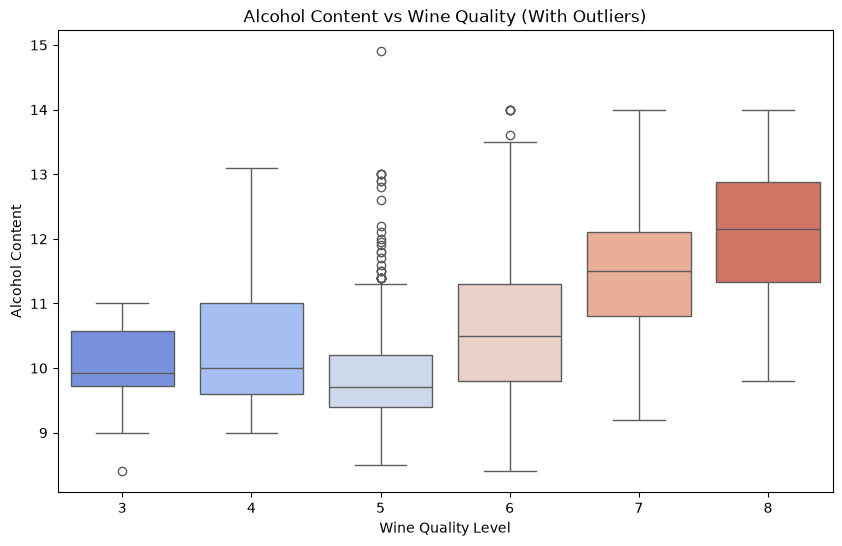

In [2]:
# boxplot version
import seaborn as sns
import matplotlib.pyplot as plt

# Example box plot for alcohol content across wine quality levels
plt.figure(figsize=(10, 6))
sns.boxplot(x='quality', y='alcohol', data=df, palette='coolwarm')
plt.title('Alcohol Content vs Wine Quality (With Outliers)')
plt.xlabel('Wine Quality Level')
plt.ylabel('Alcohol Content')
plt.show()


<Axes: >

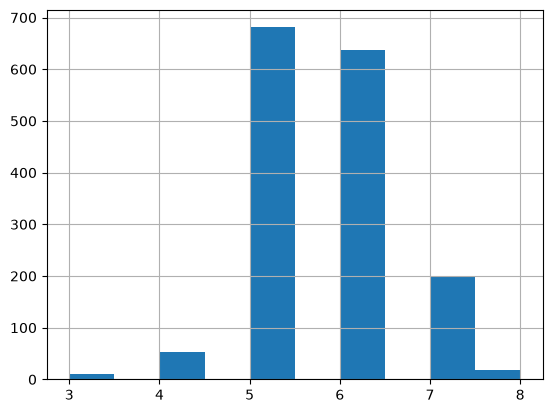

In [3]:
df['quality'].hist()

In [4]:
from imblearn.under_sampling import ClusterCentroids

# X y split to prevent data leakage
X = df.drop(columns="quality", axis=1)
y = df["quality"]

strategy = {
    3: 10,
    4: 32,
    5: 400,
    6: 400,
    7: 166,
    8: 10
}

cc = ClusterCentroids(
    sampling_strategy=strategy,
    # random_state=31555
)

X_resampled, y_resampled = cc.fit_resample(X, y)

# Make a new copy (so we don't have trouble with dependency)
df_resampled = X_resampled.copy()

# Add y back into the X rows
df_resampled["quality"] = y_resampled
df_resampled

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,10.4,0.610,0.49,2.1,0.200,5.0,16.0,0.99940,3.16,0.63,8.40,3
1,7.3,0.980,0.05,2.1,0.061,20.0,49.0,0.99705,3.31,0.55,9.70,3
2,10.4,0.440,0.42,1.5,0.145,34.0,48.0,0.99832,3.38,0.86,9.90,3
3,6.8,0.815,0.00,1.2,0.267,16.0,29.0,0.99471,3.32,0.51,9.80,3
4,6.7,0.760,0.02,1.8,0.078,6.0,12.0,0.99600,3.55,0.63,9.95,3
...,...,...,...,...,...,...,...,...,...,...,...,...
1013,7.8,0.570,0.09,2.3,0.065,34.0,45.0,0.99417,3.46,0.74,12.70,8
1014,7.2,0.380,0.31,2.0,0.056,15.0,29.0,0.99472,3.23,0.76,11.30,8
1015,5.5,0.490,0.03,1.8,0.044,28.0,87.0,0.99080,3.50,0.82,14.00,8
1016,12.6,0.310,0.72,2.2,0.072,6.0,29.0,0.99870,2.88,0.82,9.80,8


Text(0.5, 1.0, 'Original Data')

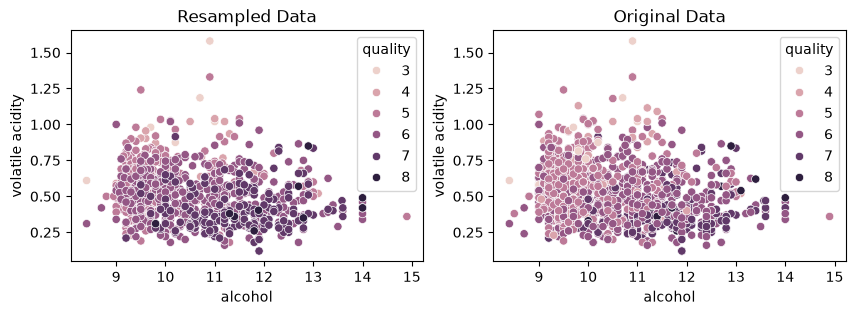

In [ ]:
# Let's look at it again. How did it perform?
fig, axes = plt.subplots(1, 2, figsize=(10, 3))

sns.scatterplot(df_resampled, x="alcohol", y='volatile acidity', hue="quality", ax=axes[0])
sns.scatterplot(df, x="alcohol", y='volatile acidity', hue="quality", ax=axes[1])    
# Not bad too, but still a little underwhelming.

axes[0].set_title("Resampled Data")
axes[1].set_title("Original Data")

# more aggressive result this time
# still, lots of overlap in the qualities 5 and 6 in the data

In [6]:
df_resampled['quality'].value_counts()

quality
6    400
5    400
7    166
4     32
3     10
8     10
Name: count, dtype: int64

C:\Users\tuomas.valtanen\AppData\Local\Temp\ipykernel_7832\2812027548.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='quality', y='alcohol', data=df_resampled, palette='coolwarm')


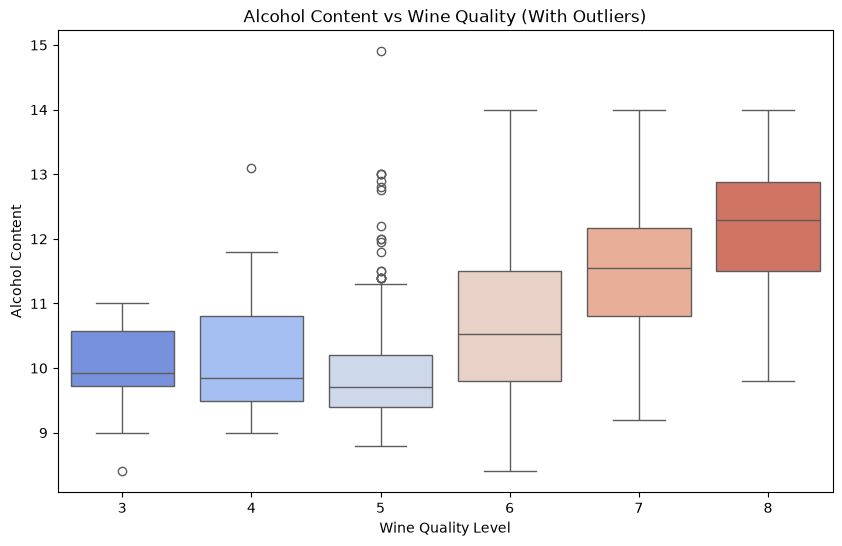

In [7]:
# boxplot version
import seaborn as sns
import matplotlib.pyplot as plt

# Example box plot for alcohol content across wine quality levels
plt.figure(figsize=(10, 6))
sns.boxplot(x='quality', y='alcohol', data=df_resampled, palette='coolwarm')
plt.title('Alcohol Content vs Wine Quality (With Outliers)')
plt.xlabel('Wine Quality Level')
plt.ylabel('Alcohol Content')
plt.show()


C:\Users\tuomas.valtanen\AppData\Local\Temp\ipykernel_7832\1118775880.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='quality', y='alcohol', data=df, palette='coolwarm')


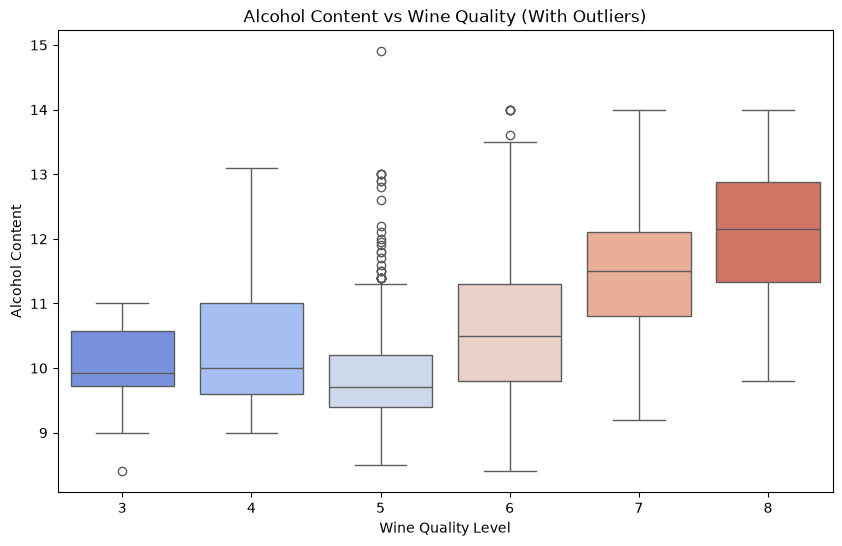

In [8]:
# boxplot version
import seaborn as sns
import matplotlib.pyplot as plt

# Example box plot for alcohol content across wine quality levels
plt.figure(figsize=(10, 6))
sns.boxplot(x='quality', y='alcohol', data=df, palette='coolwarm')
plt.title('Alcohol Content vs Wine Quality (With Outliers)')
plt.xlabel('Wine Quality Level')
plt.ylabel('Alcohol Content')
plt.show()
